In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

In [49]:
import glob
import os
import kagglehub
import pandas as pd

# 1. Baixa a versão mais recente do dataset do Kaggle
path = kagglehub.dataset_download("alanvourch/tmdb-movies-daily-updates")

# 2. Localiza automaticamente o arquivo .csv dentro da pasta baixada
csv_path = glob.glob(os.path.join(path, "*.csv"))[0]
print("Carregando:", csv_path)

# 3. Lê o CSV (low_memory=False evita avisos de tipos mistos em colunas grandes)
df = pd.read_csv(csv_path, low_memory=False)
print(f"Shape: {df.shape}")
df.head()

Carregando: C:\Users\Aline M\.cache\kagglehub\datasets\alanvourch\tmdb-movies-daily-updates\versions\1069\TMDB_all_movies.csv
Shape: (1277405, 30)


,id,title,vote_average,vote_count,status,release_date,revenue,runtime,budget,imdb_id,...,director,director_of_photography,writers,producers,music_composer,imdb_rating,imdb_votes,poster_path,keywords,certification_us
0,2,Ariel,7.100,382.0,Released,1988-10-21,0.0,73.0,0.0,tt0094675,...,Aki Kaurismäki,Timo Salminen,Aki Kaurismäki,Aki Kaurismäki,NaN,7.4,10105.0,/ojDg0PGvs6R9xYFodRct2kdI6wC.jpg,"prison|underdog|helsinki, finland|factory work...",NaN
1,3,Shadows in Paradise,7.300,457.0,Released,1986-10-17,0.0,74.0,0.0,tt0092149,...,Aki Kaurismäki,Timo Salminen,Aki Kaurismäki,Mika Kaurismäki,NaN,7.4,8934.0,/nj01hspawPof0mJmlgfjuLyJuRN.jpg,"helsinki, finland|salesclerk|garbage",NR
2,5,Four Rooms,5.900,2933.0,Released,1995-12-09,4257354.0,98.0,4000000.0,tt0113101,...,"Robert Rodriguez, Alexandre Rockwell, Allison ...","Andrzej Sekula, Guillermo Navarro, Rodrigo Gar...","Quentin Tarantino, Allison Anders, Alexandre R...","Quentin Tarantino, Alexandre Rockwell, Lawrenc...",Combustible Edison,6.7,118135.0,/75aHn1NOYXh4M7L5shoeQ6NGykP.jpg,hotel|new year's eve|witch|bet|sperm|hotel roo...,R
3,6,Judgment Night,6.455,397.0,Released,1993-10-15,12136938.0,110.0,21000000.0,tt0107286,...,Stephen Hopkins,Peter Levy,"Lewis Colick, Jere Cunningham","Gene Levy, Marilyn Vance, Lloyd Segan",Alan Silvestri,6.6,21514.0,/3rvvpS9YPM5HB2f4HYiNiJVtdam.jpg,"drug dealer|chicago, illinois|escape|one night...",R
4,8,Life in Loops (A Megacities RMX),7.300,34.0,Released,2006-01-01,0.0,80.0,42000.0,tt0825671,...,Timo Novotny,Wolfgang Thaler,"Michael Glawogger, Timo Novotny","Timo Novotny, Ulrich Gehmacher",NaN,8.1,285.0,/7ln81BRnPR2wqxuITZxEciCe1lc.jpg,megacities,NaN


Como o grafo vai seguir essas regras:

Vértices: filmes

Direção: do filme mais antigo -> filme mais recente

Conexão: Se houver atores em comum

Peso: imdb_rating do mais atual - imdb_rating do mais antigo

Decidimos remover as linhas que possuem essas colunas em branco: title, release_date, imdb_rating, cast

Decidimos remover as colunas: music_composer, tagline e certification_us por terem uma porcentagem elevada de dados ausentes e não influenciarem na nossa lógica escolhida para grafos

In [50]:

# [IA] ChatGPT – apoio com pandas para exclusão de colunas
# selecionadas e remoção de registros incompletos.

# Colunas escolhidas para exclusão após a análise de ausências
colunas_excluir = [
    "music_composer",
    "tagline",
    "certification_us"
]

# Remove as colunas selecionadas
df = df.drop(columns=colunas_excluir)

# Colunas obrigatórias para a construção do grafo
colunas_obrigatorias = [
    "title",
    "release_date",
    "imdb_rating",
    "cast"
]

# Considera textos vazios ou contendo apenas espaços como ausentes
df[colunas_obrigatorias] = df[colunas_obrigatorias].replace(
    r"^\s*$", pd.NA, regex=True
)

# Remove linhas com valores ausentes nas colunas obrigatórias
df = df.dropna(subset=colunas_obrigatorias).copy()

print("Novo tamanho do dataset:", df.shape)
print("\nValores ausentes:")
print(df.isna().sum().sort_values(ascending=False).head(15))


Novo tamanho do dataset: (416660, 27)

Valores ausentes:
keywords                   231454
director_of_photography    215502
producers                  177718
production_companies       113452
writers                     83044
production_countries        62828
spoken_languages            62346
poster_path                 33898
genres                      25156
overview                    19929
director                    12094
original_language               0
imdb_id                         0
budget                          0
runtime                         0
dtype: int64


In [51]:
df.shape

(416660, 27)

In [52]:
df.info()

<class 'pandas.DataFrame'>
Index: 416660 entries, 0 to 1276945
Data columns (total 27 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   id                       416660 non-null  int64  
 1   title                    416660 non-null  str    
 2   vote_average             416660 non-null  float64
 3   vote_count               416660 non-null  float64
 4   status                   416660 non-null  str    
 5   release_date             416660 non-null  str    
 6   revenue                  416660 non-null  float64
 7   runtime                  416660 non-null  float64
 8   budget                   416660 non-null  float64
 9   imdb_id                  416660 non-null  str    
 10  original_language        416660 non-null  str    
 11  original_title           416660 non-null  str    
 12  overview                 396731 non-null  str    
 13  popularity               416660 non-null  float64
 14  genres             

Descrição das colunas:

id: Identicador único para cada filme

title: Título oficial do filme

vote_average: Nota média do filme em uma escala de 0 a 10

vote_count: Número de votos que contribuiram para a nota do filme

Status: status atual do filme(em andamento ou já lançado)

release_date: data oficial do lançamento do filme

revenue: Receita(Arrecadação do filme nas bilheterias)

runtime: Tempo de duração do filme em minutos

budget: Orçamento destinado à produção do filme

imdb_id: Identificador do filme no IMDb

original_language: Linguagem em que o filme foi originalmente produzido

original_title: o título do filme na língua original

overview: resumo do enredo do filme

popularity: Pontuação de popularidade do filme no TMDB

genres: categorias de gêneros que o filme pertence

production_companies: Países onde o filme foi produzido

production_countries

spoken_languages: Línguas faladas no filme

cast: elenco todo

director: todos os diretores

director_of_photography: todos os diretores de fotografia

writers: todos os escritores

producers: produtores e produtores executivos

imdb_rating: Avaliação IMDB

imdb_votes: Contagem de votos IMDB

poster_path

keyworlds

In [53]:
df.describe()

,id,vote_average,vote_count,revenue,runtime,budget,popularity,imdb_rating,imdb_votes
count,4.166600e+05,416660.000000,416660.000000,4.166600e+05,416660.000000,4.166600e+05,416660.000000,416660.000000,4.166600e+05
mean,5.600050e+05,4.261596,68.036781,2.008352e+06,72.796434,7.814384e+05,1.167690,6.184511,3.234050e+03
std,4.413900e+05,3.042171,646.501860,2.886426e+07,52.833193,7.919821e+06,3.125301,1.313315,3.523480e+04
min,2.000000e+00,0.000000,0.000000,0.000000e+00,0.000000,0.000000e+00,0.000000,1.000000,5.000000e+00
25%,2.168228e+05,0.000000,0.000000,0.000000e+00,33.000000,0.000000e+00,0.337500,5.400000,2.300000e+01
50%,4.476635e+05,5.200000,2.000000,0.000000e+00,85.000000,0.000000e+00,0.823000,6.300000,7.300000e+01
75%,8.218375e+05,6.500000,9.000000,0.000000e+00,98.000000,0.000000e+00,1.433125,7.100000,3.310000e+02
max,1.833312e+06,10.000000,41977.000000,2.942661e+09,13319.000000,7.000000e+08,1233.775600,10.000000,3.266856e+06


In [54]:
df.duplicated().sum()

np.int64(0)

In [55]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)
print(df[cols_com_ausentes].isna().sum().sort_values()*100/len(df))

Colunas com ausentes: ['overview', 'genres', 'production_companies', 'production_countries', 'spoken_languages', 'director', 'director_of_photography', 'writers', 'producers', 'poster_path', 'keywords']
director                    2.902606
overview                    4.783037
genres                      6.037537
poster_path                 8.135650
spoken_languages           14.963279
production_countries       15.078961
writers                    19.930879
production_companies       27.228916
producers                  42.653002
director_of_photography    51.721308
keywords                   55.549849
dtype: float64


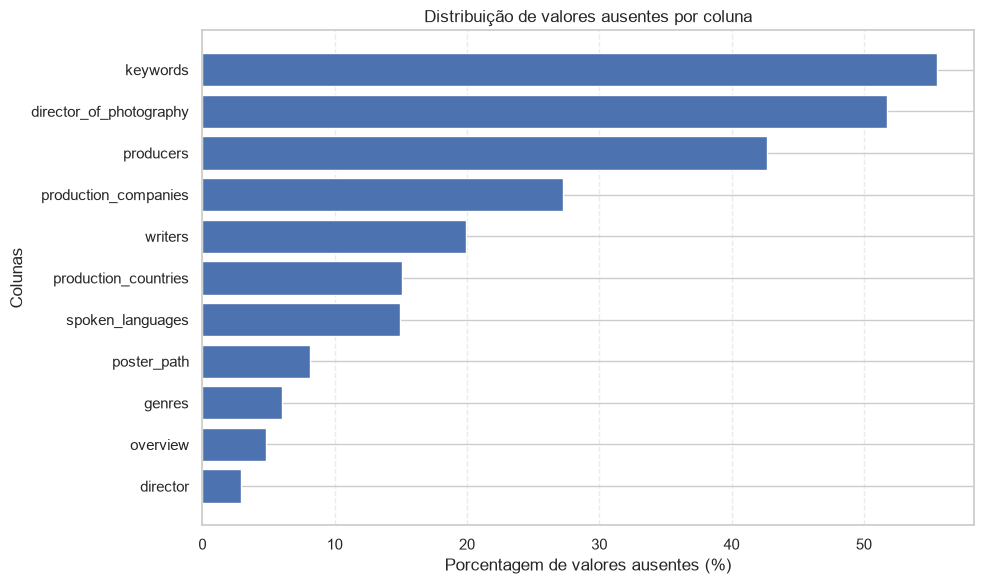

In [56]:
# Calcula a porcentagem de valores ausentes por coluna
ausentes = df.isna().sum()
percentual_ausentes = (ausentes / len(df)) * 100

# Mantém apenas as colunas que possuem valores ausentes
percentual_ausentes = percentual_ausentes[percentual_ausentes > 0]

# Ordena os valores
percentual_ausentes = percentual_ausentes.sort_values()

# Cria o gráfico
plt.figure(figsize=(10, 6))

plt.barh(
    percentual_ausentes.index,
    percentual_ausentes.values
)

plt.xlabel("Porcentagem de valores ausentes (%)")
plt.ylabel("Colunas")
plt.title("Distribuição de valores ausentes por coluna")

plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

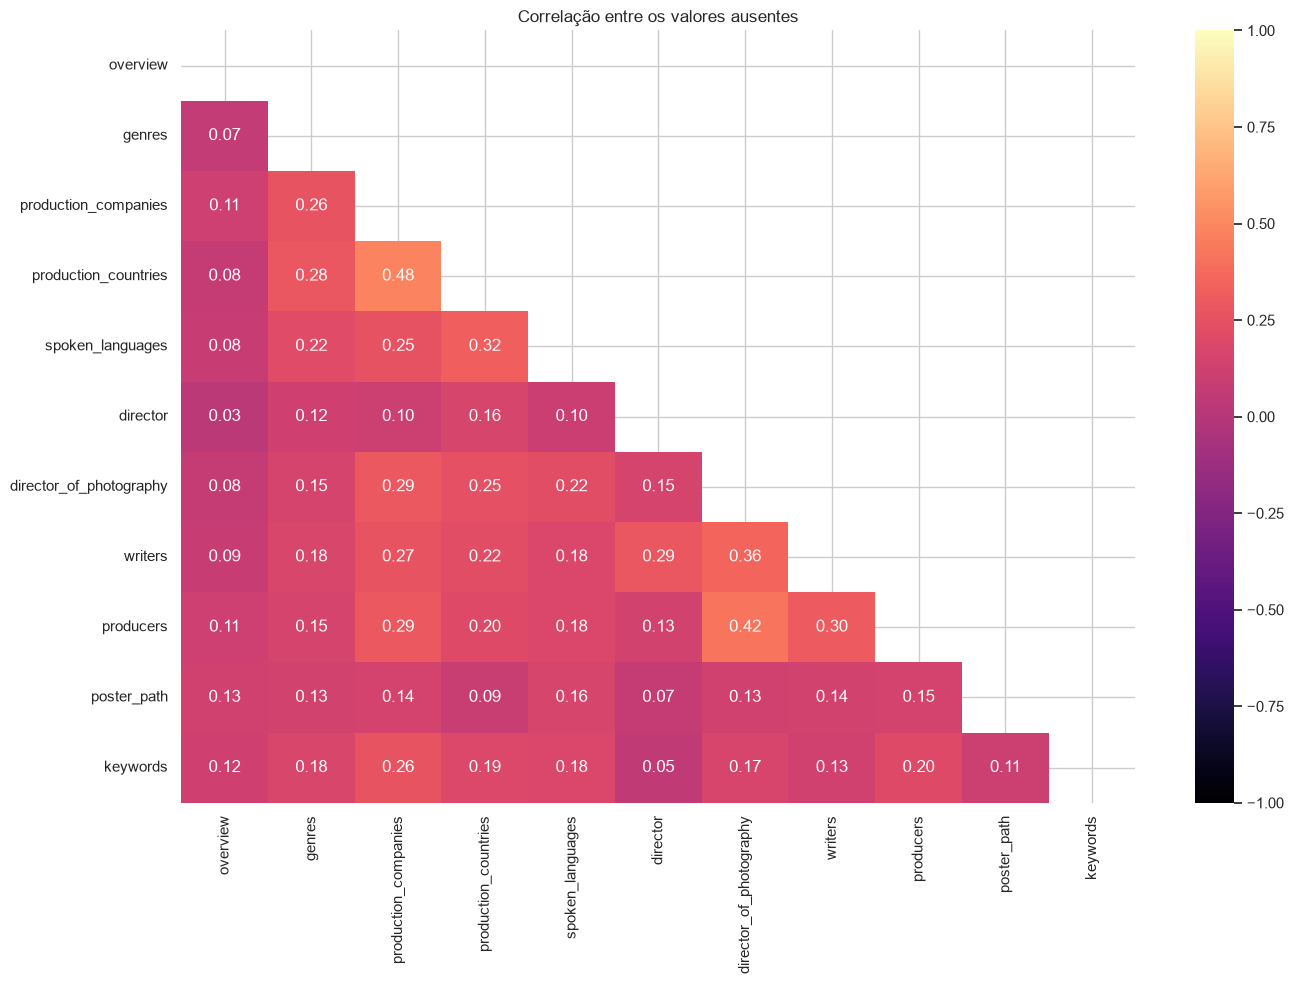

In [57]:
# Verifica quais valores estão ausentes
dados_ausentes = df[cols_com_ausentes].isna()

# Calcula a correlação entre as ausências
correlacao_ausentes = dados_ausentes.corr()

# Cria máscara para ocultar o triângulo superior
mascara = np.triu(np.ones_like(correlacao_ausentes, dtype=bool))

# Cria o gráfico
fig, ax = plt.subplots(figsize=(14, 10))

sns.heatmap(
    correlacao_ausentes,
    mask=mascara,
    annot=True,
    fmt=".2f",
    cmap="magma",
    vmin=-1,
    vmax=1,
    ax=ax
)

ax.set_title("Correlação entre os valores ausentes")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [58]:
VARS_QUANT = [
    "vote_average",
    "vote_count",
    "revenue",
    "runtime",
    "budget",
    "popularity",
    "imdb_rating",
    "imdb_votes"
]

VARS_QUALI = [
    "title",
    "status",
    "release_date",
    "original_language",
    "original_title",
    "overview",
    "genres",
    "production_companies",
    "production_countries",
    "spoken_languages",
    "cast",
    "director",
    "director_of_photography",
    "writers",
    "producers",
    "poster_path",
    "keywords"
]

VARS_QUALI_ALTA=["id","imdb_id"]

In [59]:
desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
vote_average,4.26,5.20,3.04,0.00,10.00,-0.30,-1.23
vote_count,68.04,2.00,646.50,0.00,41977.00,23.81,792.33
revenue,2008351.79,0.00,28864258.74,0.00,2942661253.00,34.71,1880.16
runtime,72.80,85.00,52.83,0.00,13319.00,69.50,16793.72
budget,781438.40,0.00,7919821.32,0.00,700000000.00,22.05,807.44
popularity,1.17,0.82,3.13,0.00,1233.78,181.45,61751.18
imdb_rating,6.18,6.30,1.31,1.00,10.00,-0.42,0.37
imdb_votes,3234.05,73.00,35234.80,5.00,3266856.00,31.75,1575.45


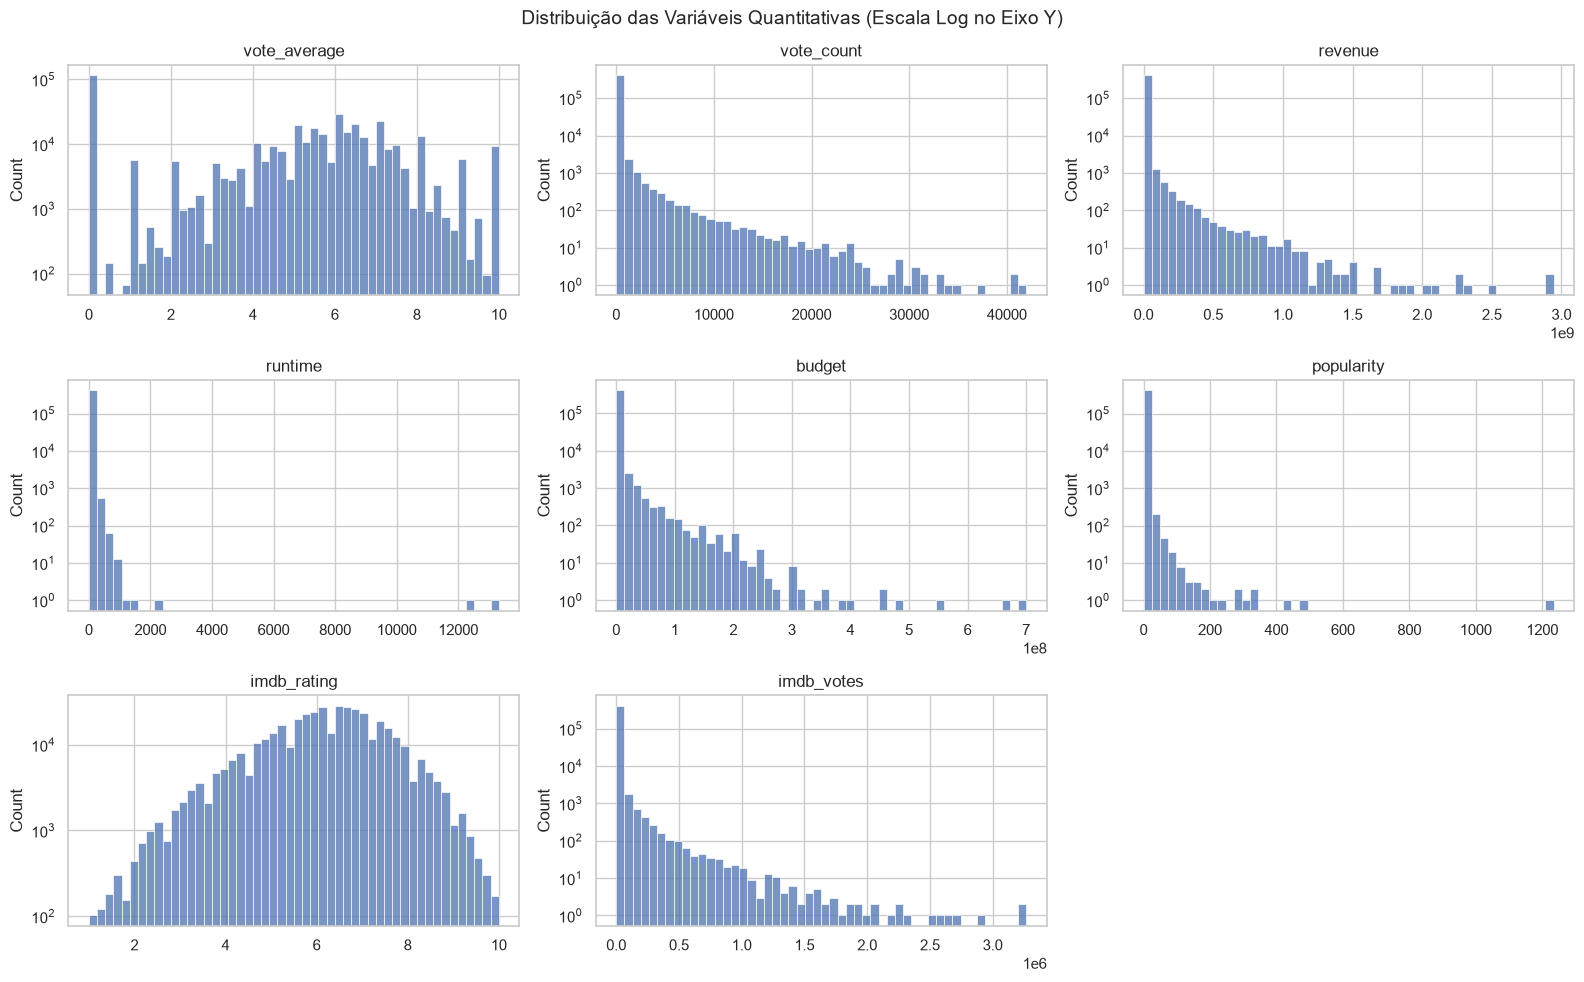

In [60]:
fig, axes = plt.subplots(3, 3, figsize=(16, 10)) # Removido sharey=True
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, bins=50, color="#4C72B0", ax=axes[i])
    axes[i].set_yscale("log") # Escala log no eixo Y para lidar com o pico de zeros
    axes[i].set_title(col)
    axes[i].set_xlabel("") # Remove label redundante abaixo de cada gráfico

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Distribuição das Variáveis Quantitativas (Escala Log no Eixo Y)", fontsize=14)
plt.tight_layout()
plt.show()

In [61]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
dispersao.round(2)

,var,std,IQR
vote_average,9.250000e+00,3.04,6.5
vote_count,4.179647e+05,646.50,9.0
revenue,8.331454e+14,28864258.74,0.0
runtime,2.791350e+03,52.83,65.0
budget,6.272357e+13,7919821.32,0.0
popularity,9.770000e+00,3.13,1.1
imdb_rating,1.720000e+00,1.31,1.7
imdb_votes,1.241491e+09,35234.80,308.0


In [62]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))


--- title ---
                         absoluta  relativa
title                                      
Mother                         53       0.0
Home                           49       0.0
Hamlet                         45       0.0
Brothers                       42       0.0
Alone                          41       0.0
...                           ...       ...
Bir Aşk Bin Günah               1       0.0
Montana Bill                    1       0.0
Brother(s)                      1       0.0
Sultan Cafe                     1       0.0
Super Duper Heist Squad         1       0.0

[358226 rows x 2 columns]

--- status ---
                 absoluta  relativa
status                             
Released           416619       1.0
Post Production        28       0.0
In Production          10       0.0
Canceled                1       0.0
Rumored                 1       0.0
Planned                 1       0.0

--- release_date ---
              absoluta  relativa
release_date               

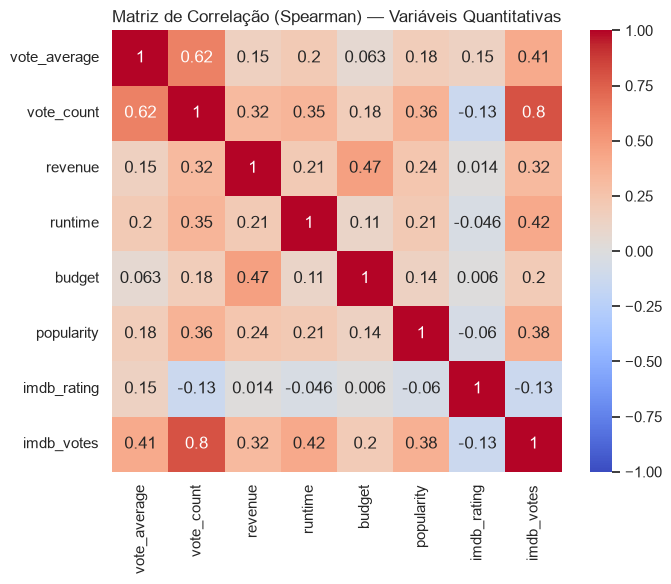

In [63]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[VARS_QUANT].corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.tight_layout()
plt.show()

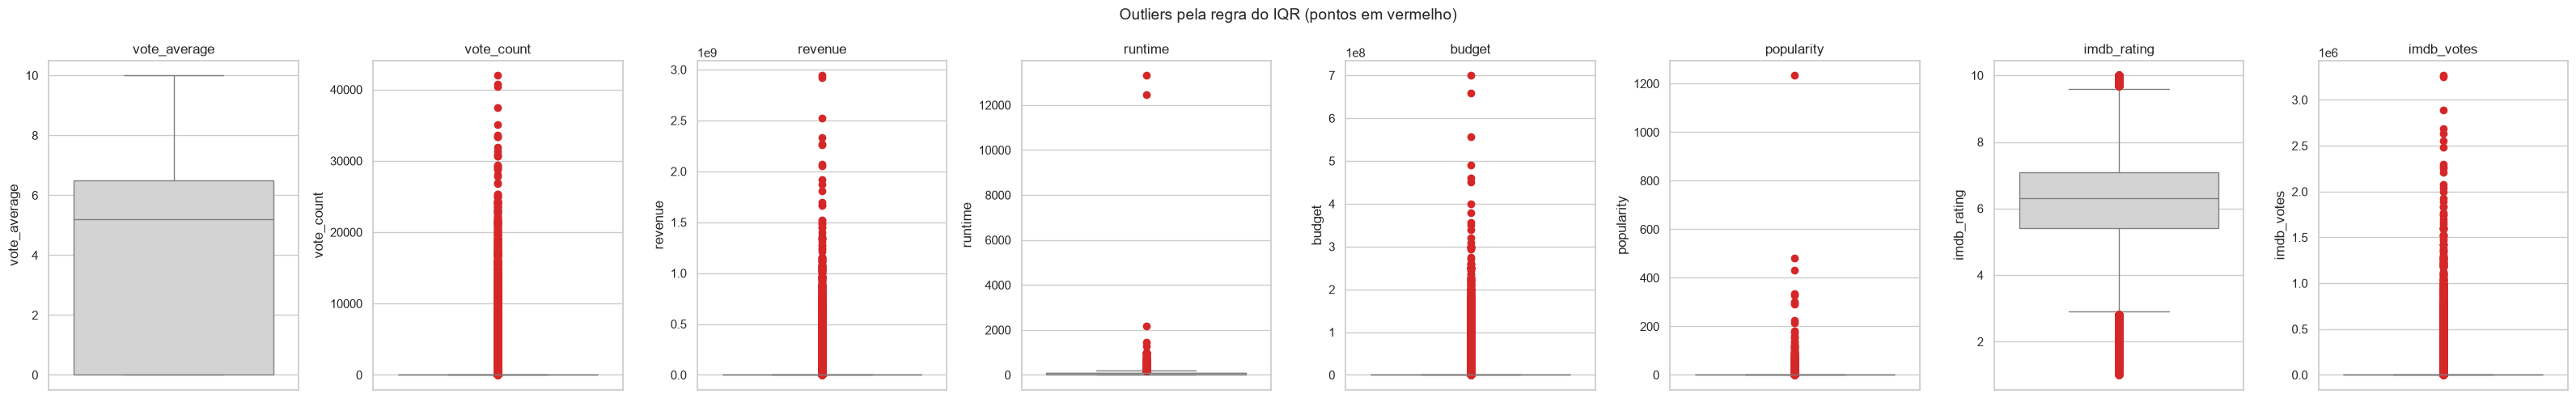

In [64]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

In [65]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
vote_average,-9.75,16.25,0.0
vote_count,-13.50,22.50,59500.0
revenue,0.00,0.00,22818.0
runtime,-64.50,195.50,2020.0
budget,0.00,0.00,35180.0
popularity,-1.31,3.08,23186.0
imdb_rating,2.85,9.65,6369.0
imdb_votes,-439.00,793.00,64379.0


A identificação de valores extremos foi realizada pelo método do intervalo interquartil (IQR). Entretanto, os valores classificados como outliers não foram automaticamente removidos, pois podem representar observações legítimas do conjunto de dados, como filmes com maior popularidade, quantidade de votos, orçamento ou receita. Assim, a decisão de tratamento considera a validade dos registros, e não apenas sua distância em relação à distribuição central.